# BigMart Sales Prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_val_predict

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from catboost import CatBoostRegressor

train = pd.read_csv("train_clean.csv")
y = train["Item_Outlet_Sales"]

print(train.shape)
train.head()

(8523, 18)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,is_train,Item_Category,Outlet_Age,Price_by_weight,Base_Price,units
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380,1,FD,14,26.861204,249.0092,15.0
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228,1,DR,4,8.153581,49.2692,9.0
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700,1,FD,14,8.092457,139.8180,15.0
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,Small,Tier 3,Grocery Store,732.3800,1,FD,15,9.484115,183.0950,4.0
4,NCD19,8.93,Non-Edible,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052,1,NC,26,6.031512,55.2614,18.0


## 5-fold cross-validation

In [2]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# a dictionary to collect all the scores
scores = {}
# one to keep each model's predictions
predictions = {}

## Model 0: baseline, predicts global avg

In [ ]:
from sklearn.metrics import root_mean_squared_error

prediction = y.mean()
guess = np.full(len(y), prediction)

scores["Overall average"] = root_mean_squared_error(y, guess)
predictions["Overall average"] = guess

print("RMSE:", scores["Overall average"])

RMSE: 1706.3995013565952


## Model 1: avg sales of each store

In [ ]:
guess = np.zeros(len(train))

for train_rows, valid_rows in kfold.split(train):
    train_data = train.iloc[train_rows]
    valid_data = train.iloc[valid_rows]

    outlet_means = train_data.groupby("Outlet_Identifier")["Item_Outlet_Sales"].mean()

    guess[valid_rows] = (
        valid_data["Outlet_Identifier"]
        .map(outlet_means)
    )

scores["Store average"] = root_mean_squared_error(y, guess)
predictions["Store average"] = guess

print("RMSE:", scores["Store average"])

RMSE: 1488.8043306435811


## Model 2: Linear Regression

Linear regression can only use numbers, so we do one-hot encoding with "pd.get_dummies"

In [ ]:
word_columns = ["Item_Fat_Content", "Item_Type", "Outlet_Identifier", "Outlet_Size",
                "Outlet_Location_Type", "Outlet_Type", "Item_Category"]

number_columns = ["Base_Price", "Item_MRP", "Item_Weight", "Item_Visibility",
                  "Outlet_Age", "Price_by_weight"]

X = train[word_columns + number_columns]
print("X shape(before):", X.shape)

X = pd.get_dummies(X, columns=word_columns)
print("X shape(after):", X.shape)

X shape(before): (8523, 13)
X shape(after): (8523, 48)


In [46]:
model = LinearRegression()
guess = cross_val_predict(model, X, y, cv=kfold)

scores["Linear Regression"] = root_mean_squared_error(y, guess)
predictions["Linear Regression"] = guess

print("RMSE:", scores["Linear Regression"])

RMSE: 1132.101388940973



## Model 3: Ridge Regression


In [45]:
model = Ridge(alpha=44.0)
guess = cross_val_predict(model, X, y, cv=kfold)

scores["Ridge"] = root_mean_squared_error(y, guess)
predictions["Ridge"] = guess

print("RMSE:", scores["Ridge"])

RMSE: 1131.6165824114494


## Model 4: Decision Tree

In [ ]:
model = DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=42)
guess = cross_val_predict(model, X, y, cv=kfold)

scores["Decision Tree"] = root_mean_squared_error(y, guess)
predictions["Decision Tree"] = guess

print("RMSE:", scores["Decision Tree"])

RMSE: 1086.9219847103286


## Model 5: Random Forest

In [ ]:
model = RandomForestRegressor(n_estimators=200, max_depth=6, min_samples_leaf=30, random_state=42, n_jobs=-1)
guess = cross_val_predict(model, X, y, cv=kfold)

scores["Random Forest"] = root_mean_squared_error(y, guess)
predictions["Random Forest"] = guess

print("RMSE:", scores["Random Forest"])

RMSE: 1081.596862110812


## Model 6: CatBoost

In [ ]:
model = CatBoostRegressor(iterations=500, learning_rate=0.03, depth=4, random_seed=42, verbose=0)
guess = cross_val_predict(model, X, y, cv=kfold)

scores["CatBoost"] = root_mean_squared_error(y, guess)
predictions["CatBoost"] = guess

print("RMSE:", scores["CatBoost"])

RMSE: 1081.525357129875


## Model 7: my own price x store rule

From Part 1: `sales = price x units`, and each store sells a steady number of units. So:

1. For each row in the training part, work out units = sales / price
2. For each store, average the units (10 numbers)
3. Prediction = price x the store's average units

No fancy library is needed, just a groupby.

In [ ]:
guess = np.zeros(len(train))

for train_rows, valid_rows in kfold.split(train):
    train_data = train.iloc[train_rows]
    valid_data = train.iloc[valid_rows]

    units = train_data["Item_Outlet_Sales"] / train_data["Base_Price"]
    store_rate = units.groupby(train_data["Outlet_Identifier"]).mean()

    guess[valid_rows] = (
        valid_data["Base_Price"] *
        valid_data["Outlet_Identifier"].map(store_rate)
    )

scores["Price x store rate"] = root_mean_squared_error(y, guess)
predictions["Price x store rate"] = guess

print("RMSE:", scores["Price x store rate"])

RMSE: 1071.5121492941496


## All the scores

Price x store rate                1071.51
Price x store rate (noisy MRP)    1071.97
CatBoost                          1081.53
Random Forest                     1081.60
Decision Tree                     1086.92
Ridge                             1131.62
Linear Regression                 1132.10
Store average                     1488.80
Overall average                   1706.40
dtype: float64


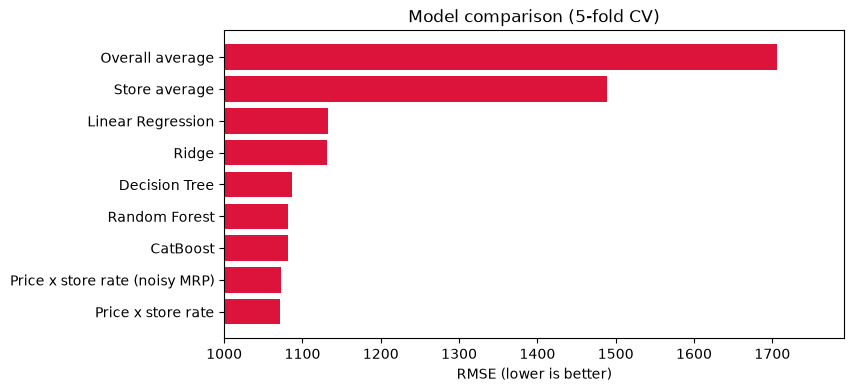

In [47]:
table = pd.Series(scores).sort_values()
print(table.round(2))

plt.figure(figsize=(8, 4))
plt.barh(table.index, table.values, color="crimson")
plt.xlim(1000)

plt.xlabel("RMSE (lower is better)")
plt.title("Model comparison (5-fold CV)")
plt.show()